# Experiment No. 9: Customer Segmentation using K-Means and Hierarchical Clustering

**Name:** Kamal Man  
**Section-Batch:** A-A1  
**Roll No:** 11


## 1. Import Libraries

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster, cophenet
from scipy.spatial.distance import pdist

sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42

## 2. Load the Dataset

In [2]:
import os
path = "Wholesale customers data.csv"
if not os.path.exists(path):
    path = "Wholesale_customers_data.csv"   # alternate file name
df = pd.read_csv(path)
print("Shape:", df.shape)
df.head()

Shape: (440, 8)


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


## 3. Data Preprocessing

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 440 entries, 0 to 439
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Channel           440 non-null    int64
 1   Region            440 non-null    int64
 2   Fresh             440 non-null    int64
 3   Milk              440 non-null    int64
 4   Grocery           440 non-null    int64
 5   Frozen            440 non-null    int64
 6   Detergents_Paper  440 non-null    int64
 7   Delicassen        440 non-null    int64
dtypes: int64(8)
memory usage: 27.6 KB


In [4]:
print("Missing values per column:\n", df.isnull().sum(), "\n")
print("Duplicate rows:", df.duplicated().sum())

Missing values per column:
 Channel             0
Region              0
Fresh               0
Milk                0
Grocery             0
Frozen              0
Detergents_Paper    0
Delicassen          0
dtype: int64 

Duplicate rows: 0


In [5]:
spend_cols = ["Fresh", "Milk", "Grocery", "Frozen", "Detergents_Paper", "Delicassen"]
df["Channel_Name"] = df["Channel"].map({1: "Horeca", 2: "Retail"})
df["Region_Name"] = df["Region"].map({1: "Lisbon", 2: "Oporto", 3: "Other"})
df["Total_Spend"] = df[spend_cols].sum(axis=1)
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Channel,440.0,1.322727,0.468052,1.0,1.00,1.0,2.00,2.0
Region,440.0,2.543182,0.774272,1.0,2.00,3.0,3.00,3.0
Fresh,440.0,12000.297727,12647.328865,3.0,3127.75,8504.0,16933.75,112151.0
Milk,440.0,5796.265909,7380.377175,55.0,1533.00,3627.0,7190.25,73498.0
Grocery,440.0,7951.277273,9503.162829,3.0,2153.00,4755.5,10655.75,92780.0
Frozen,440.0,3071.931818,4854.673333,25.0,742.25,1526.0,3554.25,60869.0
Detergents_Paper,440.0,2881.493182,4767.854448,3.0,256.75,816.5,3922.00,40827.0
Delicassen,440.0,1524.870455,2820.105937,3.0,408.25,965.5,1820.25,47943.0
Total_Spend,440.0,33226.136364,26356.301730,904.0,17448.75,27492.0,41307.50,199891.0


## 4. Exploratory Data Analysis (EDA)

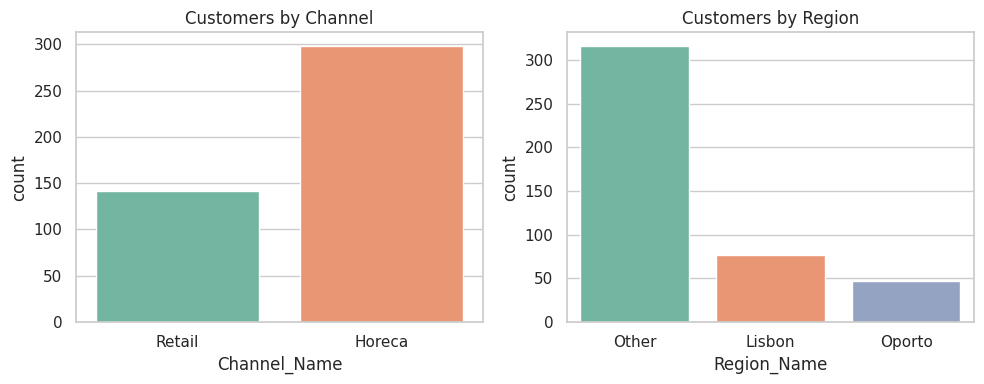

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.countplot(data=df, x="Channel_Name", ax=axes[0], palette="Set2")
axes[0].set_title("Customers by Channel")
sns.countplot(data=df, x="Region_Name", ax=axes[1], palette="Set2")
axes[1].set_title("Customers by Region")
plt.tight_layout(); plt.show()

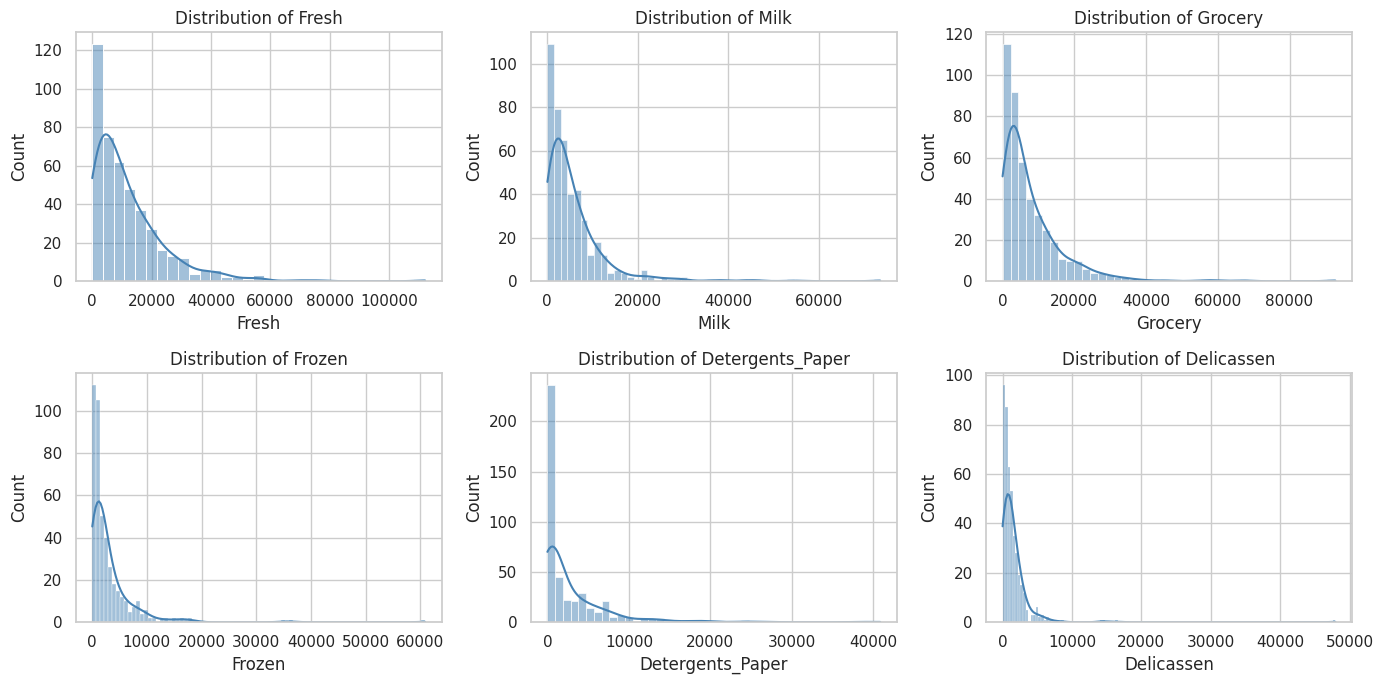

Skewness:
 Fresh                2.56
Milk                 4.05
Grocery              3.59
Frozen               5.91
Detergents_Paper     3.63
Delicassen          11.15
dtype: float64


In [7]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.ravel(), spend_cols):
    sns.histplot(df[col], kde=True, ax=ax, color="steelblue")
    ax.set_title(f"Distribution of {col}")
plt.tight_layout(); plt.show()
print("Skewness:\n", df[spend_cols].skew().round(2))

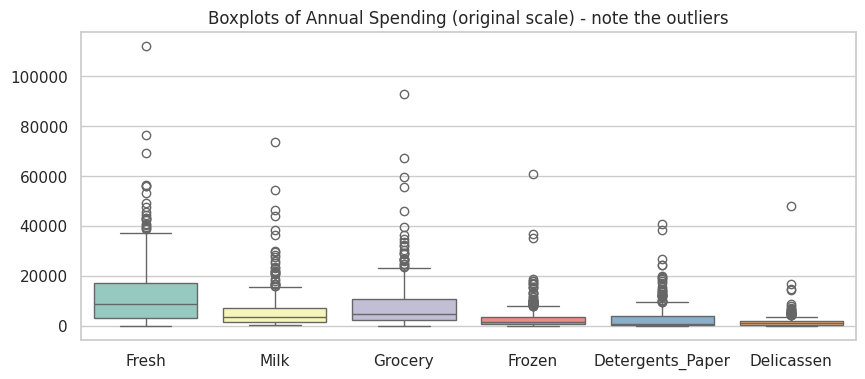

In [8]:
plt.figure(figsize=(10, 4))
sns.boxplot(data=df[spend_cols], palette="Set3")
plt.title("Boxplots of Annual Spending (original scale) - note the outliers")
plt.show()

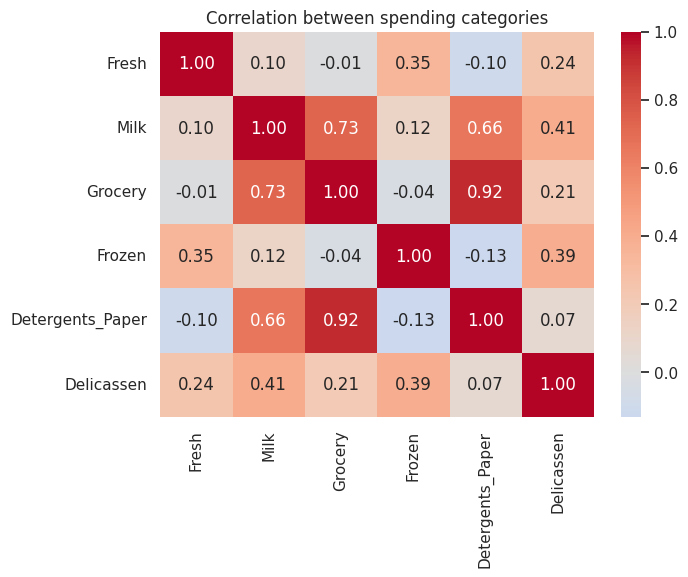

In [9]:
plt.figure(figsize=(7, 5))
sns.heatmap(df[spend_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation between spending categories")
plt.show()

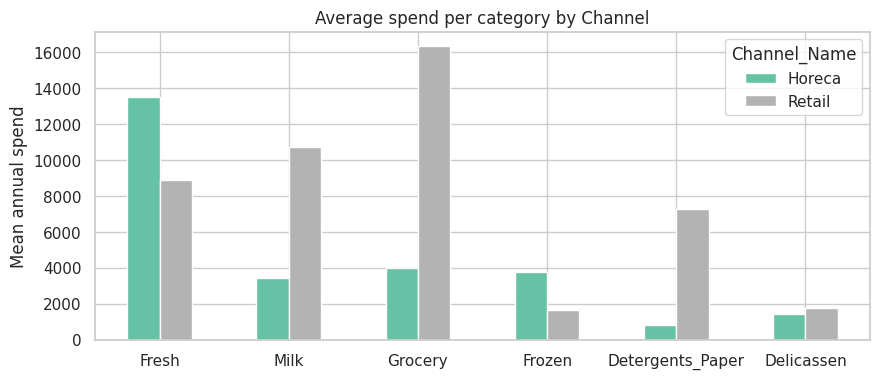

In [10]:
df.groupby("Channel_Name")[spend_cols].mean().round(0).T.plot(kind="bar", figsize=(10, 4), colormap="Set2")
plt.title("Average spend per category by Channel")
plt.ylabel("Mean annual spend"); plt.xticks(rotation=0)
plt.show()

## 5. Feature Scaling


In [11]:
X_log = np.log1p(df[spend_cols])
scaler = StandardScaler()
X = scaler.fit_transform(X_log)
X_scaled = pd.DataFrame(X, columns=spend_cols)

print("Skewness before:", df[spend_cols].skew().round(2).to_dict())
print("Skewness after :", X_log.skew().round(2).to_dict())
print("\nScaled means (approx 0):", X_scaled.mean().round(3).to_dict())
print("Scaled std   (approx 1):", X_scaled.std(ddof=0).round(3).to_dict())

Skewness before: {'Fresh': 2.56, 'Milk': 4.05, 'Grocery': 3.59, 'Frozen': 5.91, 'Detergents_Paper': 3.63, 'Delicassen': 11.15}
Skewness after : {'Fresh': -1.58, 'Milk': -0.22, 'Grocery': -0.67, 'Frozen': -0.35, 'Detergents_Paper': -0.24, 'Delicassen': -1.09}

Scaled means (approx 0): {'Fresh': 0.0, 'Milk': -0.0, 'Grocery': -0.0, 'Frozen': 0.0, 'Detergents_Paper': -0.0, 'Delicassen': -0.0}
Scaled std   (approx 1): {'Fresh': 1.0, 'Milk': 1.0, 'Grocery': 1.0, 'Frozen': 1.0, 'Detergents_Paper': 1.0, 'Delicassen': 1.0}


## 6. Determine the Optimal Number of Clusters

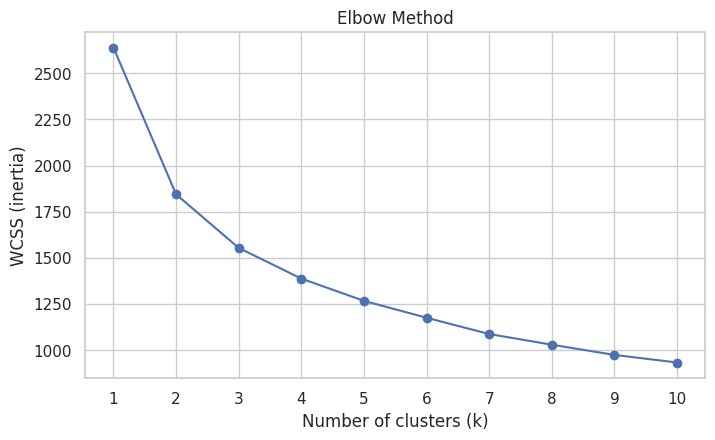

,k,WCSS,Drop vs previous
0,1,2640.0,NaN
1,2,1844.1,795.9
2,3,1553.4,290.6
3,4,1386.9,166.6
4,5,1266.1,120.7
5,6,1174.8,91.4
6,7,1086.4,88.4
7,8,1028.5,57.9
8,9,973.1,55.3
9,10,932.0,41.1


In [12]:
k_range = range(1, 11)
wcss = []
for k in k_range:
    km = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=RANDOM_STATE)
    km.fit(X)
    wcss.append(km.inertia_)

plt.figure(figsize=(8, 4.5))
plt.plot(list(k_range), wcss, marker="o")
plt.xlabel("Number of clusters (k)"); plt.ylabel("WCSS (inertia)")
plt.title("Elbow Method")
plt.xticks(list(k_range)); plt.grid(True)
plt.show()
pd.DataFrame({"k": list(k_range), "WCSS": np.round(wcss, 1),
              "Drop vs previous": [np.nan] + list(np.round(-np.diff(wcss), 1))})

### 6.2 Silhouette Score (cross-check)

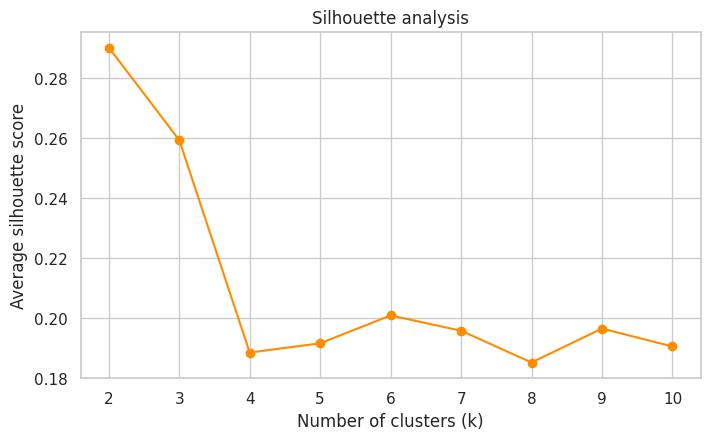

2     0.2903
3     0.2594
4     0.1885
5     0.1916
6     0.2009
7     0.1958
8     0.1852
9     0.1965
10    0.1905


In [13]:
sil = []
ks = range(2, 11)
for k in ks:
    labels = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit_predict(X)
    sil.append(silhouette_score(X, labels))

plt.figure(figsize=(8, 4.5))
plt.plot(list(ks), sil, marker="o", color="darkorange")
plt.xlabel("Number of clusters (k)"); plt.ylabel("Average silhouette score")
plt.title("Silhouette analysis"); plt.xticks(list(ks)); plt.grid(True)
plt.show()
print(pd.Series(np.round(sil, 4), index=list(ks), name="silhouette").to_string())

In [14]:
# Choose k automatically from the elbow (largest second difference of the WCSS curve)
# and report the silhouette-best k alongside it.
second_diff = np.diff(wcss, 2)
k_elbow = int(np.argmax(second_diff) + 2)
k_sil = int(list(ks)[int(np.argmax(sil))])
print("k suggested by elbow (max curvature):", k_elbow)
print("k with best silhouette score        :", k_sil)

k suggested by elbow (max curvature): 2
k with best silhouette score        : 2


## 7. K-Means Clustering


In [15]:
K = 3   # chosen from the elbow curve + silhouette scores (k=2 is best, k=3 is the next best and gives a richer segmentation)
kmeans = KMeans(n_clusters=K, init="k-means++", n_init=20, random_state=RANDOM_STATE)
df["KMeans_Cluster"] = kmeans.fit_predict(X)

print("Cluster sizes (K-Means):")
print(df["KMeans_Cluster"].value_counts().sort_index())
print("\nInertia:", round(kmeans.inertia_, 2))

Cluster sizes (K-Means):
KMeans_Cluster
0    145
1    212
2     83
Name: count, dtype: int64

Inertia: 1553.41


## 8. Hierarchical Clustering

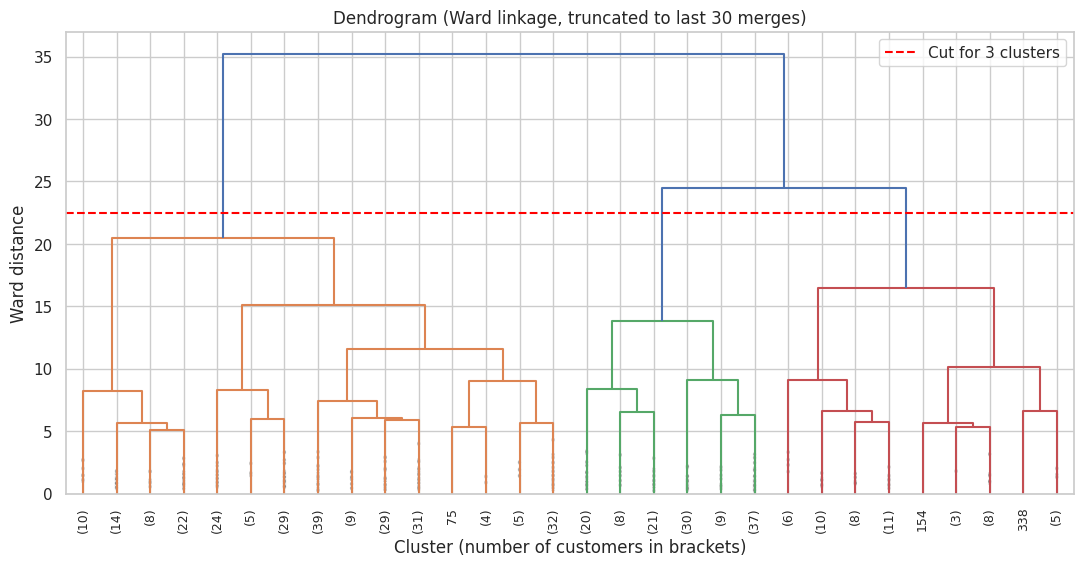

In [16]:
Z = linkage(X, method="ward")

plt.figure(figsize=(13, 6))
dendrogram(Z, truncate_mode="lastp", p=30, leaf_rotation=90., leaf_font_size=9,
           show_contracted=True, color_threshold=Z[-(K - 1), 2])
cut_height = (Z[-(K - 1), 2] + Z[-K, 2]) / 2
plt.axhline(cut_height, color="red", linestyle="--", label=f"Cut for {K} clusters")
plt.title("Dendrogram (Ward linkage, truncated to last 30 merges)")
plt.xlabel("Cluster (number of customers in brackets)"); plt.ylabel("Ward distance")
plt.legend(); plt.show()

In [17]:
# Which linkage method gives the best cophenetic correlation (how faithfully the tree preserves distances)?
d = pdist(X)
for method in ["ward", "complete", "average", "single"]:
    c, _ = cophenet(linkage(X, method=method), d)
    print(f"{method:9s} cophenetic correlation = {c:.4f}")

ward      cophenetic correlation = 0.4841
complete  cophenetic correlation = 0.6536
average   cophenetic correlation = 0.7452
single    cophenetic correlation = 0.6493


### 8.2 Agglomerative Clustering

In [18]:
agg = AgglomerativeClustering(n_clusters=K, linkage="ward")
df["HC_Cluster"] = agg.fit_predict(X)
print("Cluster sizes (Hierarchical):")
print(df["HC_Cluster"].value_counts().sort_index())

Cluster sizes (Hierarchical):
HC_Cluster
0    262
1     53
2    125
Name: count, dtype: int64


## 9. Visualising the Customer Segments
The data has six dimensions, so we project it to 2-D with **PCA** purely for plotting. Clustering was done on all six scaled features.

Variance explained by PC1, PC2: [0.441 0.272] | total = 0.713


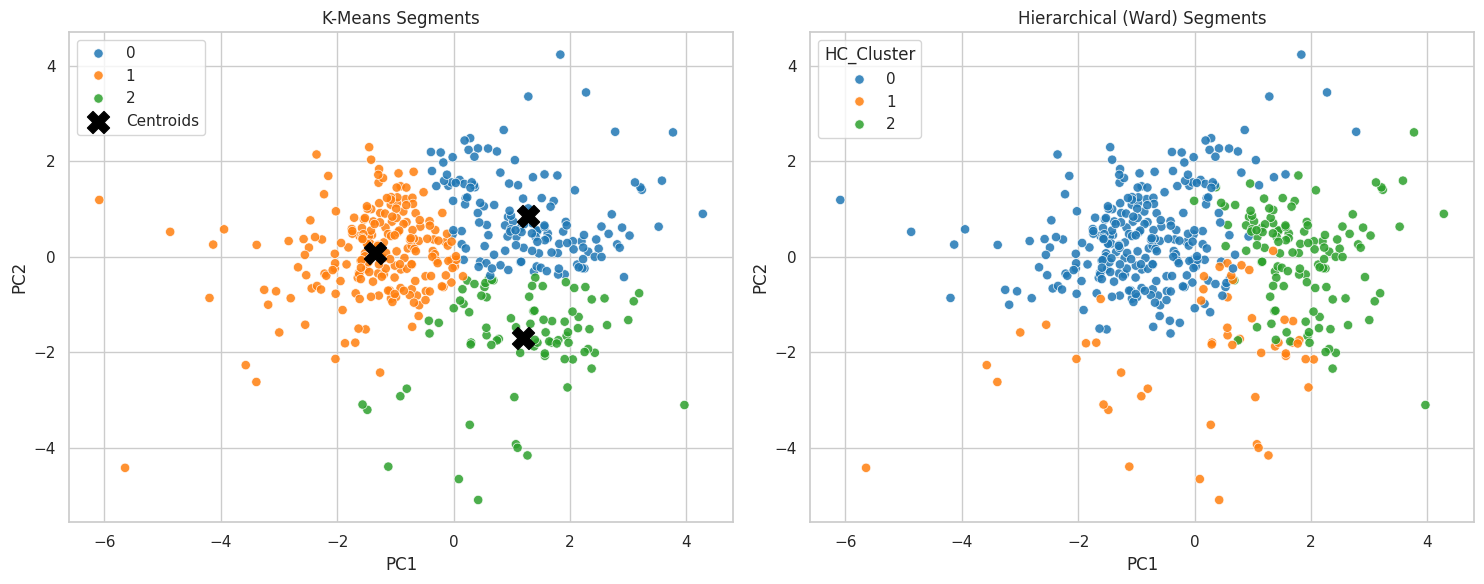

In [19]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
pcs = pca.fit_transform(X)
df["PC1"], df["PC2"] = pcs[:, 0], pcs[:, 1]
print("Variance explained by PC1, PC2:", pca.explained_variance_ratio_.round(3),
      "| total =", pca.explained_variance_ratio_.sum().round(3))

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, col, title in zip(axes, ["KMeans_Cluster", "HC_Cluster"],
                          ["K-Means Segments", "Hierarchical (Ward) Segments"]):
    sns.scatterplot(data=df, x="PC1", y="PC2", hue=col, palette="tab10", s=45, ax=ax, alpha=0.85)
    ax.set_title(title)
# mark K-Means centroids
cent = pca.transform(kmeans.cluster_centers_)
axes[0].scatter(cent[:, 0], cent[:, 1], c="black", marker="X", s=250, label="Centroids")
axes[0].legend()
plt.tight_layout(); plt.show()

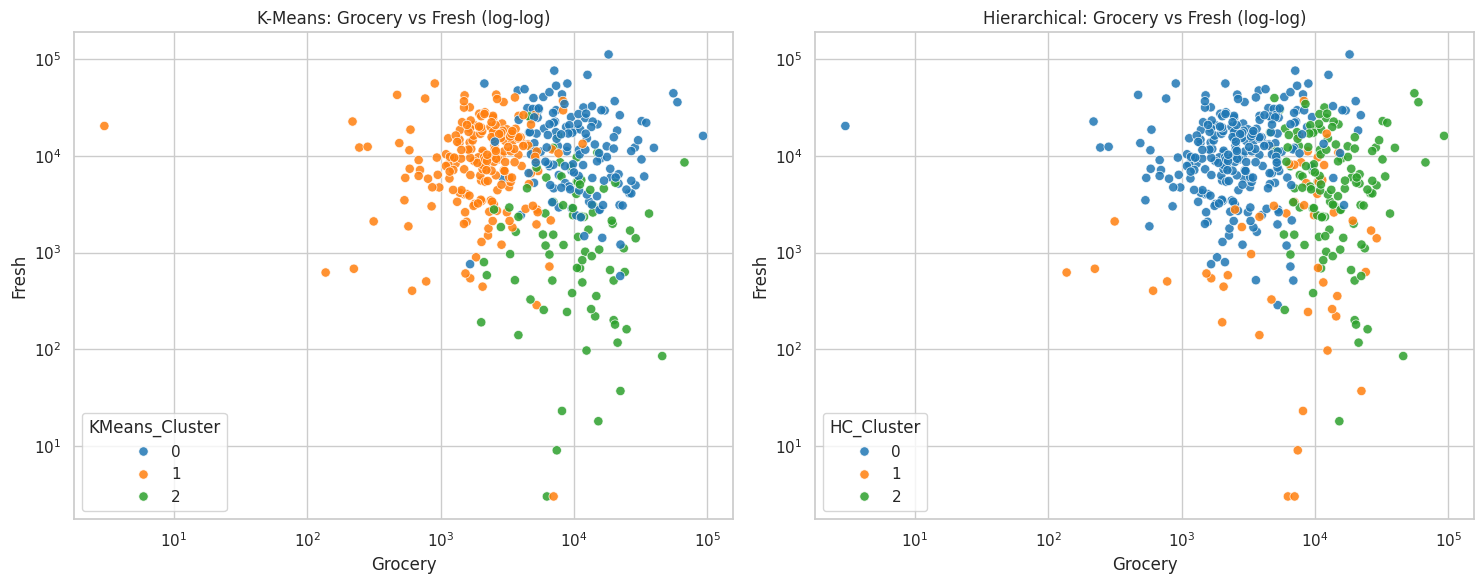

In [20]:
# Segments in terms of two original spending features (log scale)
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, col, title in zip(axes, ["KMeans_Cluster", "HC_Cluster"], ["K-Means", "Hierarchical"]):
    sns.scatterplot(data=df, x="Grocery", y="Fresh", hue=col, palette="tab10", s=45, ax=ax, alpha=0.85)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_title(f"{title}: Grocery vs Fresh (log-log)")
plt.tight_layout(); plt.show()

## 10. Comparison of K-Means and Hierarchical Clustering

In [21]:
def evaluate(labels):
    return {"Silhouette (higher better)": silhouette_score(X, labels),
            "Davies-Bouldin (lower better)": davies_bouldin_score(X, labels),
            "Calinski-Harabasz (higher better)": calinski_harabasz_score(X, labels)}

comparison = pd.DataFrame({"K-Means": evaluate(df["KMeans_Cluster"]),
                           "Hierarchical (Ward)": evaluate(df["HC_Cluster"])}).round(4)
comparison

,K-Means,Hierarchical (Ward)
Silhouette (higher better),0.2583,0.2547
Davies-Bouldin (lower better),1.3482,1.5390
Calinski-Harabasz (higher better),152.8372,116.7993


In [22]:
ari = adjusted_rand_score(df["KMeans_Cluster"], df["HC_Cluster"])
print(f"Adjusted Rand Index between the two clusterings: {ari:.4f}  (1 = identical)")

print("\nCross-tabulation (rows = K-Means, columns = Hierarchical):")
ct = pd.crosstab(df["KMeans_Cluster"], df["HC_Cluster"])
ct

Adjusted Rand Index between the two clusterings: 0.4422  (1 = identical)

Cross-tabulation (rows = K-Means, columns = Hierarchical):


HC_Cluster,0,1,2
KMeans_Cluster,,,
0,49,6,90
1,201,11,0
2,12,36,35


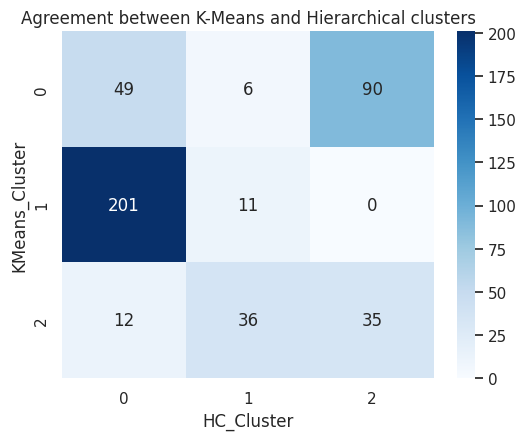

In [23]:
fig, ax = plt.subplots(figsize=(6, 4.5))
sns.heatmap(ct, annot=True, fmt="d", cmap="Blues", ax=ax)
ax.set_title("Agreement between K-Means and Hierarchical clusters")
plt.show()

In [24]:
# External sanity check: how well does each clustering align with the known Channel?
print("ARI vs Channel  - K-Means     :", round(adjusted_rand_score(df['Channel'], df['KMeans_Cluster']), 4))
print("ARI vs Channel  - Hierarchical:", round(adjusted_rand_score(df['Channel'], df['HC_Cluster']), 4))

ARI vs Channel  - K-Means     : 0.3456
ARI vs Channel  - Hierarchical: 0.5487


In [25]:
print("Run-time comparison")
import time
t = time.time(); KMeans(n_clusters=K, n_init=20, random_state=RANDOM_STATE).fit(X); t_km = time.time() - t
t = time.time(); AgglomerativeClustering(n_clusters=K, linkage="ward").fit(X); t_hc = time.time() - t
print(f"K-Means      : {t_km:.4f} s")
print(f"Hierarchical : {t_hc:.4f} s")

Run-time comparison
K-Means      : 0.0635 s
Hierarchical : 0.0099 s


## 11. Cluster Profiling and Business Insights

In [26]:
# Mean ORIGINAL spend per K-Means cluster (easier to interpret than scaled values)
profile = df.groupby("KMeans_Cluster")[spend_cols].mean().round(0)
profile["Customers"] = df["KMeans_Cluster"].value_counts().sort_index()
profile["Avg_Total_Spend"] = df.groupby("KMeans_Cluster")["Total_Spend"].mean().round(0)
profile["% Retail"] = (df.groupby("KMeans_Cluster")["Channel"].apply(lambda s: (s == 2).mean()) * 100).round(1)
profile

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,Customers,Avg_Total_Spend,% Retail
KMeans_Cluster,,,,,,,,,
0,17182.0,10658.0,13381.0,4181.0,5004.0,2867.0,145,53273.0,61.4
1,11993.0,1995.0,2497.0,3278.0,426.0,893.0,212,21081.0,1.4
2,2967.0,7011.0,12397.0,608.0,5446.0,795.0,83,29225.0,60.2


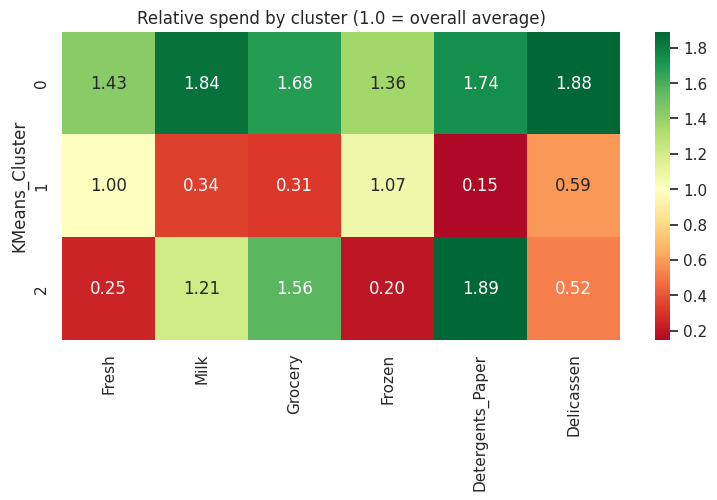

In [27]:
# Heatmap of relative spend: each cluster mean divided by the overall mean (1.0 = average customer)
rel = df.groupby("KMeans_Cluster")[spend_cols].mean() / df[spend_cols].mean()
plt.figure(figsize=(9, 4))
sns.heatmap(rel, annot=True, fmt=".2f", cmap="RdYlGn", center=1)
plt.title("Relative spend by cluster (1.0 = overall average)")
plt.show()

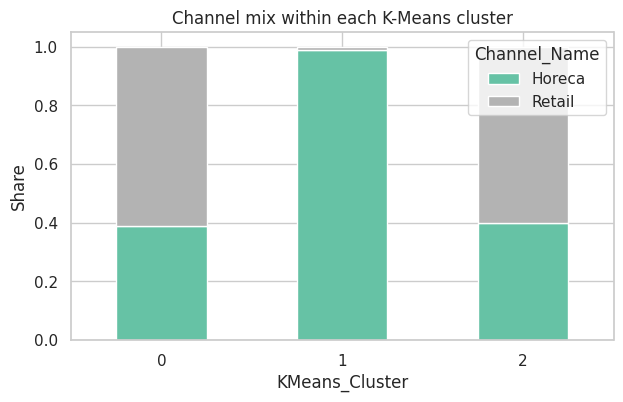

In [28]:
pd.crosstab(df["KMeans_Cluster"], df["Channel_Name"], normalize="index").round(2).plot(
    kind="bar", stacked=True, figsize=(7, 4), colormap="Set2")
plt.title("Channel mix within each K-Means cluster"); plt.ylabel("Share"); plt.xticks(rotation=0)
plt.show()